In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
# Load the Shampoo Sales dataset

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/shampoo.csv"

df = pd.read_csv(url)

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

First 5 rows of the dataset:


,Month,Sales
0,1-01,266.0
1,1-02,145.9
2,1-03,183.1
3,1-04,119.3
4,1-05,180.3


Dataset Shape: (36, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Month   36 non-null     object 
 1   Sales   36 non-null     float64
dtypes: float64(1), object(1)
memory usage: 708.0+ bytes


In [3]:
# Statistical summary
print("Statistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Statistical Summary:


,Sales
count,36.000000
mean,312.600000
std,148.937164
min,119.300000
25%,192.450000
50%,280.150000
75%,411.100000
max,682.000000



Missing Values:
Month    0
Sales    0
dtype: int64


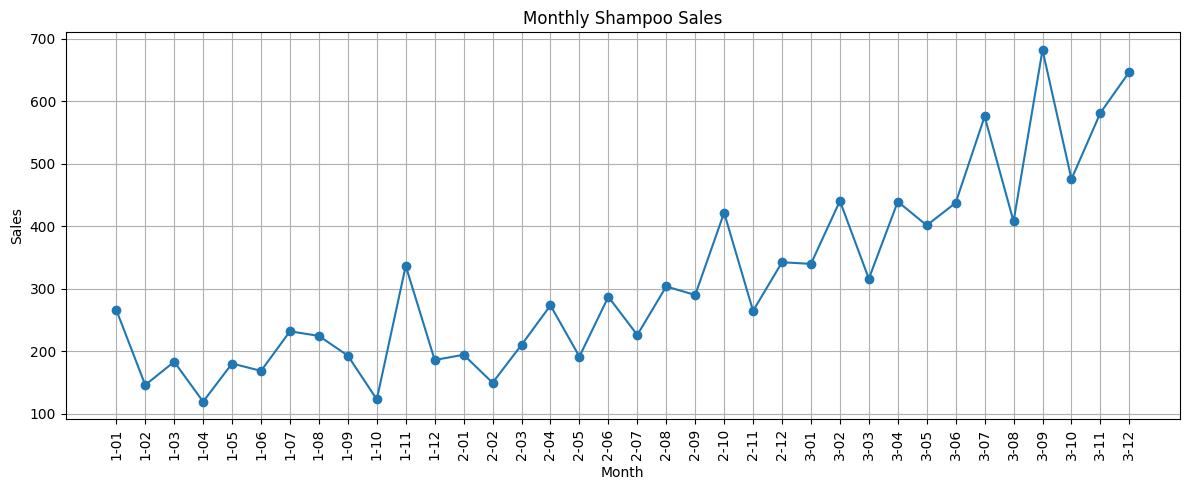

In [4]:
# Visualize monthly shampoo sales

plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"],
    df["Sales"],
    marker="o"
)

plt.title("Monthly Shampoo Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

In [5]:
# Extract sales values
sales = df["Sales"].values.reshape(-1, 1)

# Split data chronologically (80% training, 20% testing)
train_size = int(len(sales) * 0.80)

# Normalize the data using MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Fit scaler only on training data to avoid data leakage
scaler.fit(sales[:train_size])

sales_scaled = scaler.transform(sales)

print("Original data shape:", sales.shape)
print("Normalized data shape:", sales_scaled.shape)
print("Training records:", train_size)
print("Testing records:", len(sales) - train_size)

print("\nFirst 5 normalized values:")
print(sales_scaled[:5])

Original data shape: (36, 1)
Normalized data shape: (36, 1)
Training records: 28
Testing records: 8

First 5 normalized values:
[[0.45686702]
 [0.08284024]
 [0.198692  ]
 [0.        ]
 [0.18997197]]


In [6]:
# Create sequences for LSTM
look_back = 3

X = []
y = []

for i in range(look_back, len(sales_scaled)):
    X.append(sales_scaled[i-look_back:i, 0])
    y.append(sales_scaled[i, 0])

X = np.array(X)
y = np.array(y)

# Split sequences chronologically
X_train = X[:train_size-look_back]
X_test = X[train_size-look_back:]

y_train = y[:train_size-look_back]
y_test = y[train_size-look_back:]

# Reshape input for LSTM
X_train = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_test = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (25, 3, 1)
X_test shape: (8, 3, 1)
y_train shape: (25,)
y_test shape: (8,)


In [7]:
# Build the LSTM model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3, 1)),

    tf.keras.layers.LSTM(50, activation='tanh'),

    tf.keras.layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Train the LSTM model

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    verbose=1
)

print("Model training completed!")

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2437
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1816 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1380 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0964 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0731 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0585 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0532 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0522 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0517 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0519 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0515
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0509 
Epoch 13/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0506 
Epoch 14/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0504 
Epoch 15/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0502 
Epoch 16/100
7/7 ━━━

In [9]:
# Predict sales using the trained LSTM model

predictions = model.predict(X_test)

# Convert normalized values back to original sales values
predicted_sales = scaler.inverse_transform(predictions)

actual_sales = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# Display predictions
results = pd.DataFrame({
    "Actual Sales": actual_sales.flatten(),
    "Predicted Sales": predicted_sales.flatten()
})

display(results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step


,Actual Sales,Predicted Sales
0,401.3,375.320923
1,437.4,411.347626
2,575.5,425.514862
3,407.6,467.339783
4,682.0,530.288330
5,475.3,498.216583
6,581.3,607.722656
7,646.9,535.008972


In [10]:
# Calculate MAE and RMSE

mae = mean_absolute_error(
    actual_sales,
    predicted_sales
)

rmse = np.sqrt(
    mean_squared_error(
        actual_sales,
        predicted_sales
    )
)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

Mean Absolute Error (MAE): 71.84
Root Mean Squared Error (RMSE): 89.57


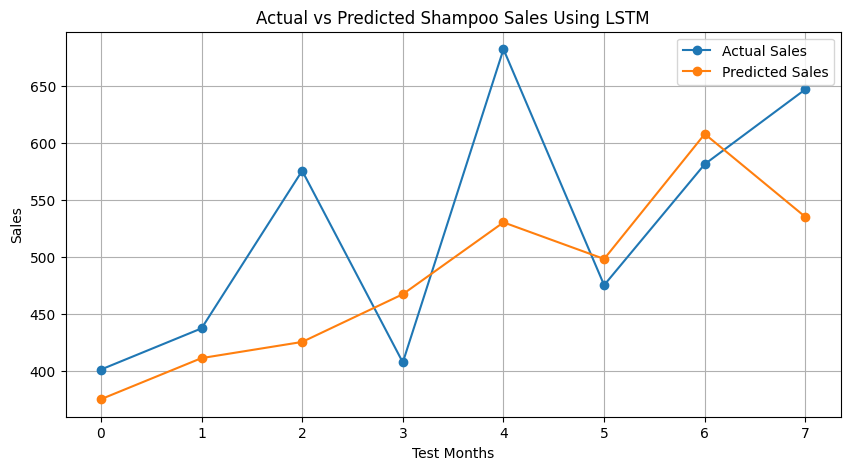

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    actual_sales,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    predicted_sales,
    label="Predicted Sales",
    marker="o"
)

plt.title("Actual vs Predicted Shampoo Sales Using LSTM")
plt.xlabel("Test Months")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

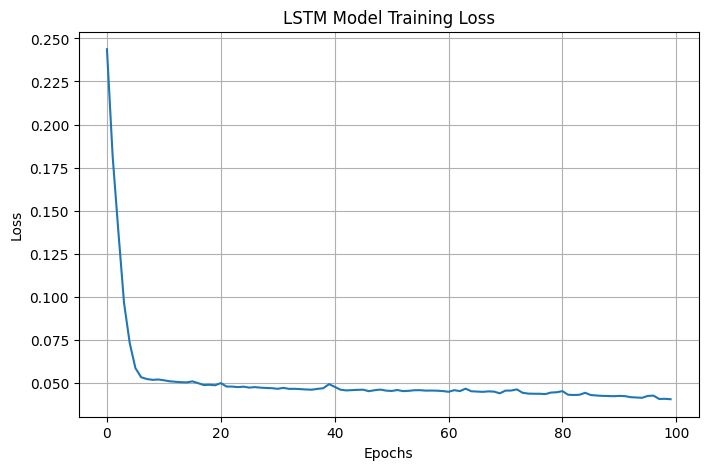

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"])

plt.title("LSTM Model Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.grid(True)
plt.show()

## Analysis

### 1. Dataset Analysis

The Monthly Shampoo Sales dataset contains 36 monthly observations. The sales graph shows an overall increasing trend with fluctuations over time.

### 2. LSTM Model

An LSTM model was developed using TensorFlow/Keras. It consists of an LSTM layer with 50 units and a Dense output layer.

The model uses the previous 3 months of sales data to predict the next month's sales.

The model was trained for 100 epochs using the Adam optimizer and Mean Squared Error loss.

### 3. Model Evaluation

The model was evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

- MAE: 71.84
- RMSE: 89.57

These metrics measure the difference between actual and predicted sales values.

### 4. Training Loss Analysis

The training loss graph shows a significant decrease during the initial epochs. After that, the loss gradually stabilizes, indicating that the model is learning from the training data.

### 5. Prediction Analysis

The actual and predicted sales values were compared using a line graph. This visualization helps evaluate how closely the LSTM model follows the actual sales trend.

## Conclusion

An LSTM-based time-series forecasting model was successfully developed using the Monthly Shampoo Sales dataset.

The dataset was loaded, explored, normalized, and converted into sequences for LSTM input. The model was trained using TensorFlow/Keras and used to predict future sales values.

The model was evaluated using MAE and RMSE, and actual versus predicted sales were visualized.

This assignment provided practical understanding of time-series preprocessing, LSTM architecture, model training, prediction, and evaluation.